# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [2]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [7]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [8]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [11]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [12]:

# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [13]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [14]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [15]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [16]:

# cantidad de nulos para users
print("Cantidad de valores nulos:")
print(users.isna().sum())

print("Proporción de valores nulos:")
print(users.isna().mean())

Cantidad de valores nulos:
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
Proporción de valores nulos:
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [17]:
# cantidad de nulos para usage
print("Cantidad de valores nulos:")
print(usage.isna().sum())

print("Proporción de valores nulos:")
print(usage.isna().mean())

Cantidad de valores nulos:
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
Proporción de valores nulos:
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


### Diagnóstico de valores nulos

- **Dataset `users`:** La columna `city` presenta 469 valores nulos (11,73 %). Se recomienda investigar su origen y evaluar si pueden recuperarse; si no es posible, conservarlos como nulos para no inventar información. La columna `churn_date` tiene 3.534 valores nulos (88,35 %), que podrían corresponder a clientes que no han cancelado el servicio. Se recomienda verificar esta interpretación y conservar los nulos si representan clientes activos.

- **Dataset `usage`:** La columna `date` presenta 50 valores nulos (0,125 %). Se recomienda investigar si las fechas pueden recuperarse y, si no, evaluar estos registros según su utilidad para el análisis temporal. Las columnas `duration` (55,19 % de nulos) y `length` (44,74 %) presentan una alta proporción de valores ausentes; se debe comprobar si estos corresponden a tipos de actividad distintos —llamadas y mensajes— antes de decidir su tratamiento.

- **Dataset `plans`:** No presenta valores nulos, por lo que no requiere tratamiento en esta etapa.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [18]:
# explorar columnas numéricas de users
users[['user_id', 'age']].describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000



- La columna `user_id` presenta 4.000 registros y valores entre 10.000 y 13.999. El rango parece consistente con identificadores consecutivos; se recomienda verificar que no existan duplicados.
- La columna `age` presenta un valor mínimo de -999, que se considera inválido y posible valor centinela. Se recomienda identificar los registros afectados y tratar ese valor como dato ausente antes de calcular estadísticas y segmentar por edad.

In [19]:
usage[['id', 'user_id', 'duration', 'length']].describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id` presentan valores entre 1 y 40.000, y entre 10.000 y 13.999, respectivamente. Los rangos parecen razonables; se recomienda verificar la unicidad de `id` y la correspondencia de `user_id` con la tabla de clientes.
- Las columnas `duration` y `length` presentan mínimos de cero y máximos de 120 y 1.490, respectivamente. Se recomienda investigar los registros con valores cero y extremos antes de decidir si son inválidos, pues podrían corresponder a comportamientos reales o a inconsistencias de registro.

In [24]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

for columna in columnas_user:
    print(f'\nValores de {columna}:')
    print(users[columna].value_counts(dropna=False))


Valores de city:
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

Valores de plan:
Basico     2595
Premium    1405
Name: plan, dtype: int64



- La columna `city` presenta seis categorías de ciudades (Bogotá, CDMX, Medellín, GDL, Cali y MTY), además de 469 valores nulos y 96 registros con el símbolo `?`, que se considera un posible valor centinela. Se recomienda investigar estos registros y estandarizar `?` como valor ausente si se confirma que representa una ciudad desconocida.

- La columna `plan` contiene únicamente dos categorías: `Basico` (2.595 clientes) y `Premium` (1.405 clientes). Los valores coinciden con los planes identificados en el catálogo, por lo que no se observan inconsistencias categóricas en esta exploración.

In [20]:

# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

for columna in columnas_user:
    print(f'\nValores de {columna}:')
    print(users[columna].value_counts(dropna=False))


Valores de city:
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

Valores de plan:
Basico     2595
Premium    1405
Name: plan, dtype: int64


- La columna `type` identifica dos categorías de actividad: llamadas (`call`) y mensajes (`text`). Estos valores corresponden a los tipos de uso esperados en el análisis, por lo que no se observan categorías inválidas en esta revisión.


In [25]:
# explorar columna categórica de usage
print(usage['type'].value_counts(dropna=False))

text    22092
call    17908
Name: type, dtype: int64



- **Columna `age` de `users`:** se identificó el valor -999, que no representa una edad válida y se considera un posible centinela. Se recomienda reemplazarlo por un valor ausente y excluirlo de los cálculos de edad hasta determinar si se puede recuperar la información.
- **Columna `city` de `users`:** se encontraron 96 registros con el símbolo `?`, además de 469 valores ausentes. Se recomienda tratar `?` como valor ausente si se confirma que representa una ciudad desconocida, e investigar si es posible recuperar esos datos.
- **Columna `plan` de `users`:** presenta únicamente las categorías `Basico` y `Premium`, que coinciden con el catálogo de planes. No se identifican inconsistencias categóricas.
- **Columnas `duration` y `length` de `usage`:** presentan valores mínimos de cero y máximos de 120 y 1.490, respectivamente. Se recomienda revisar los registros extremos y los valores cero antes de decidir si son inválidos.
- **Columnas `id` y `user_id` de `usage`:** los rangos parecen razonables, pero se debe verificar la unicidad de `id` y la correspondencia de `user_id` con los clientes registrados.
- **Columna `type` de `usage`:** contiene 22.092 registros `text` y 17.908 registros `call`. Ambas categorías son esperadas, por lo que no se observan valores categóricos inválidos en esta exploración.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [27]:

# Convertir a fecha la columna 'reg_date' de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [28]:

# Convertir a fecha la columna 'date' de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [29]:
# Revisar los años presentes en 'reg_date' de users
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()


2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date`, se observan registros de 2022 (1.314), 2023 (1.316), 2024 (1.330) y 2026 (40). Como el periodo del proyecto llega hasta 2024, las 40 fechas de 2026 están fuera del rango esperado. Se recomienda revisar esos registros y confirmar si corresponden a errores de captura antes de corregirlos o excluirlos del análisis.

In [30]:
# Revisar los años presentes en 'date' de usage
usage['date'].dt.year.value_counts(dropna=False).sort_index()


2024.0    39950
NaN          50
Name: date, dtype: int64


En `date`, se identifican 39.950 registros con fecha válida correspondientes a 2024 y 50 valores ausentes. Se recomienda investigar si las fechas faltantes pueden recuperarse y excluir esos registros únicamente de los análisis temporales que requieran una fecha válida, conservándolos para otros análisis si resultan útiles.


- Se identificaron 40 fechas de registro de clientes correspondientes a 2026, posteriores al periodo de análisis establecido hasta 2024. Se recomienda revisar los registros afectados y corregirlos únicamente si se confirma un error; de lo contrario, excluirlos de los análisis limitados al periodo definido.
- En `usage['date']` se encontraron 50 fechas ausentes y no se observaron otros años fuera de 2024 entre los registros válidos. Se recomienda investigar si las fechas pueden recuperarse y considerar estos registros sin fecha en los análisis temporales.


---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [31]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [32]:

# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print(users['city'].value_counts(dropna=False))

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64


In [33]:

# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())

2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [34]:
# Verificación MAR en usage (Missing At Random) para duration
# Verificación de nulos en duration por tipo
print(pd.crosstab(usage['type'], usage['duration'].isna()))

duration  False  True 
type                  
call      17908      0
text         16  22076


In [36]:
# Verificación MAR en usage (Missing At Random) para length
# Verificación de nulos en length por tipo
print(pd.crosstab(usage['type'], usage['length'].isna()))

length  False  True 
type                
call       12  17896
text    22092      0


- **Columna `duration`:** los 22.076 valores nulos se concentran en los registros de tipo `text`, mientras que las 17.908 llamadas tienen duración registrada. Este patrón indica que los nulos dependen del tipo de actividad y son esperables para los mensajes. Se recomienda conservarlos como nulos, sin imputar duraciones artificiales, e investigar los 16 mensajes que sí presentan duración.

- **Columna `length`:** los 17.896 valores nulos se concentran en los registros de tipo `call`, mientras que los 22.092 mensajes tienen longitud registrada. Este patrón es coherente con la naturaleza de cada actividad. Se recomienda conservar los nulos y revisar las 12 llamadas que presentan longitud registrada.

- **Conclusión:** los valores ausentes de `duration` y `length` parecen corresponder principalmente a ausencias estructurales asociadas al tipo de actividad. Antes de realizar análisis específicos de estas variables, se deben investigar los registros que no siguen el patrón esperado.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [38]:

# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int)
usage["is_call"] = (usage["type"] == "call").astype(int)

# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg(
    cant_mensajes=("is_text", "sum"),
    cant_llamadas=("is_call", "sum"),
    cant_minutos_llamada=("duration", "sum")
).reset_index()

# Observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [39]:
# Renombrar columnas

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [41]:

# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(
    usage_agg,
    on='user_id',
    how='left'
)

# Observar resultado
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [42]:
# Resumen estadístico de las columnas numéricas
columnas_numericas = [
    'age',
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

user_profile[columnas_numericas].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [43]:
# Distribución porcentual del tipo de plan
# Distribución porcentual del tipo de plan
(user_profile['plan'].value_counts(normalize=True) * 100).round(2)


Basico     64.88
Premium    35.12
Name: plan, dtype: float64

Diagnóstico del resumen estadístico

La edad promedio de los clientes es de 48,14 años, con una mediana de 48 y un rango entre 18 y 79 años. En cuanto al uso, se registran en promedio 5,52 mensajes, 4,48 llamadas y 23,32 minutos de llamadas por usuario. La diferencia entre el promedio y la mediana de la duración sugiere posibles valores extremos que deben revisarse. Respecto a los planes, el 64,88 % de los clientes pertenece al plan Básico y el 35,12 % al Premium. Estos resultados constituyen una primera descripción del perfil de los usuarios y deberán complementarse con visualizaciones y análisis de segmentación.

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

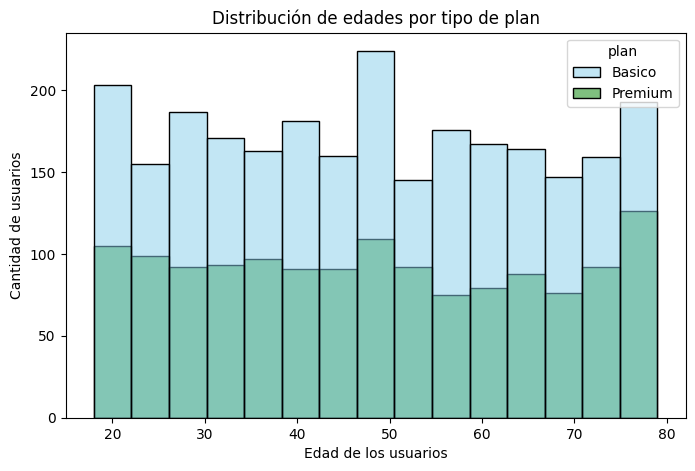

In [44]:

# Histograma para visualizar la edad (age)
plt.figure(figsize=(8, 5))

sns.histplot(
    data=user_profile,
    x='age',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=15
)

plt.title('Distribución de edades por tipo de plan')
plt.xlabel('Edad de los usuarios')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- **Distribución de edades:** los clientes se distribuyen aproximadamente entre los 18 y 79 años, sin una concentración exclusiva en un solo rango etario.
- **Comparación por plan:** el plan Básico presenta mayores frecuencias absolutas en los intervalos de edad observados, lo cual es coherente con su mayor participación en la base de clientes (64,88 % frente al 35,12 % de Premium).
- **Interpretación:** para determinar si existen diferencias en la estructura de edades entre los planes, sería conveniente comparar las distribuciones porcentuales de cada grupo.

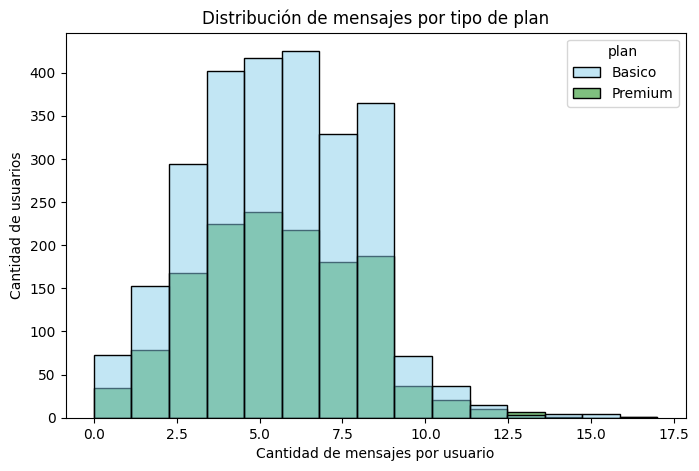

In [45]:

# Histograma para visualizar la cantidad de mensajes
plt.figure(figsize=(8, 5))

sns.histplot(
    data=user_profile,
    x='cant_mensajes',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=15
)

plt.title('Distribución de mensajes por tipo de plan')
plt.xlabel('Cantidad de mensajes por usuario')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- **Distribución:** la mayor concentración de usuarios se encuentra aproximadamente entre 3 y 8 mensajes. La distribución presenta una asimetría hacia la derecha, debido a que hay menos usuarios con cantidades elevadas de mensajes.
- **Comparación por plan:** el plan Básico presenta frecuencias absolutas superiores a las del Premium en la mayoría de los intervalos, en concordancia con su mayor participación en la base de clientes.
- **Interpretación:** se recomienda comparar las distribuciones porcentuales de cada plan para determinar si existen diferencias reales en los patrones de mensajería, más allá del tamaño de cada grupo.

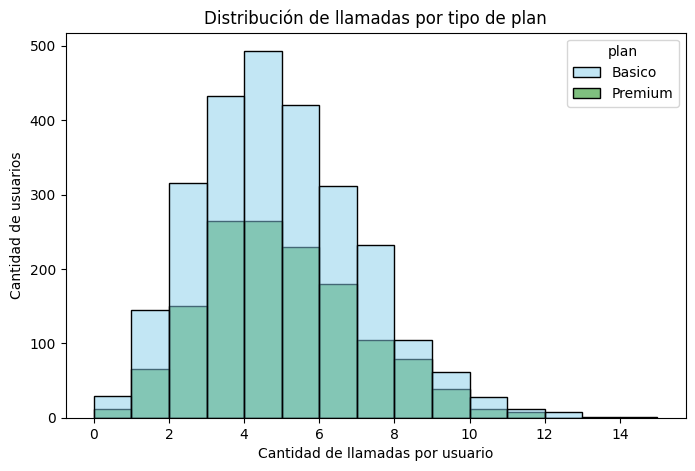

In [46]:

# Histograma para visualizar la cantidad de llamadas
plt.figure(figsize=(8, 5))

sns.histplot(
    data=user_profile,
    x='cant_llamadas',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=15
)

plt.title('Distribución de llamadas por tipo de plan')
plt.xlabel('Cantidad de llamadas por usuario')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- **Distribución:** la mayor concentración de usuarios se encuentra aproximadamente entre 2 y 7 llamadas, con un pico cercano a 4 llamadas por usuario. La distribución presenta una asimetría hacia la derecha.
- **Comparación por plan:** el plan Básico muestra frecuencias absolutas mayores en la mayoría de los intervalos, en concordancia con su mayor número de clientes.
- **Interpretación:** se recomienda comparar las proporciones de cada plan y revisar los registros con mayor número de llamadas para determinar si representan comportamientos de consumo inusuales.

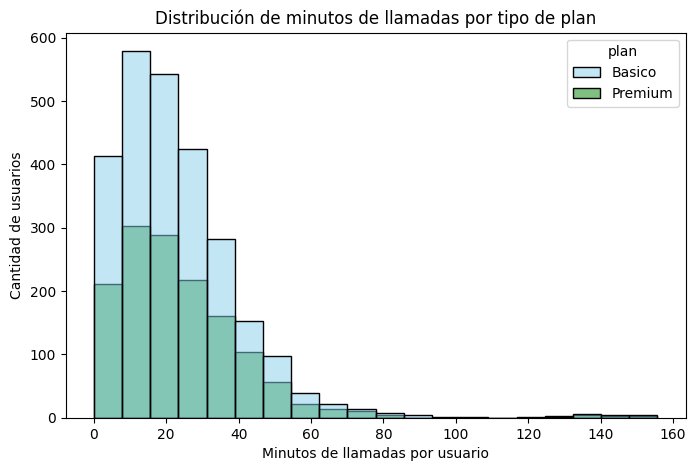

In [47]:
# Histograma para visualizar la cant_minutos_llamada
plt.figure(figsize=(8, 5))

sns.histplot(
    data=user_profile,
    x='cant_minutos_llamada',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=20
)

plt.title('Distribución de minutos de llamadas por tipo de plan')
plt.xlabel('Minutos de llamadas por usuario')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- **Distribución:** la mayor concentración de usuarios se encuentra aproximadamente entre 5 y 40 minutos de llamadas, especialmente entre 10 y 25 minutos. La distribución presenta una marcada asimetría hacia la derecha.
- **Comparación por plan:** el plan Básico presenta mayores frecuencias absolutas en la mayoría de los intervalos, lo cual es coherente con su mayor número de clientes.
- **Valores extremos:** se observan pocos usuarios con duraciones superiores a 100 minutos. Se recomienda revisar estos registros mediante métodos estadísticos, como el rango intercuartílico (IQR), para determinar si corresponden a valores atípicos.
- **Interpretación comercial:** identificar usuarios con consumos elevados podría ayudar a comprender necesidades diferenciadas y evaluar oportunidades de ajuste en la oferta de planes.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

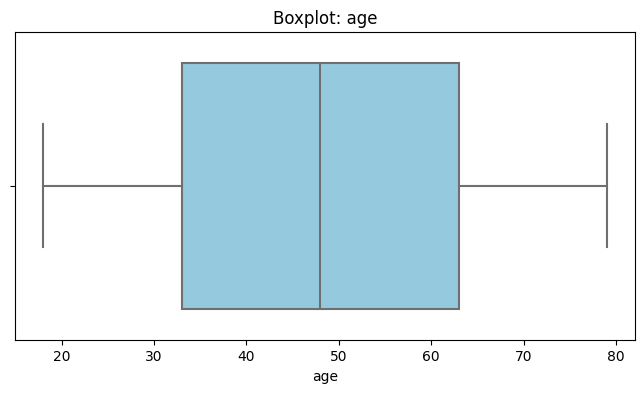

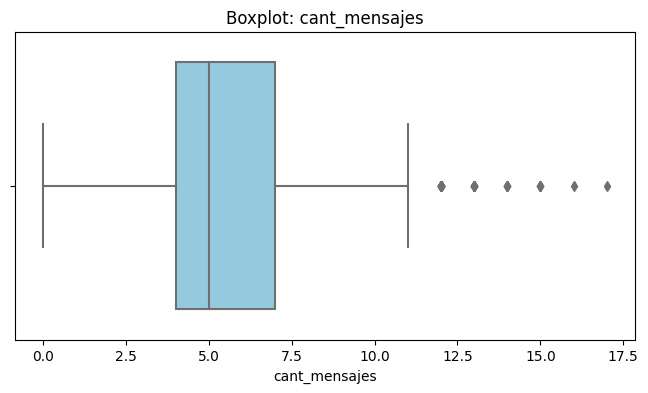

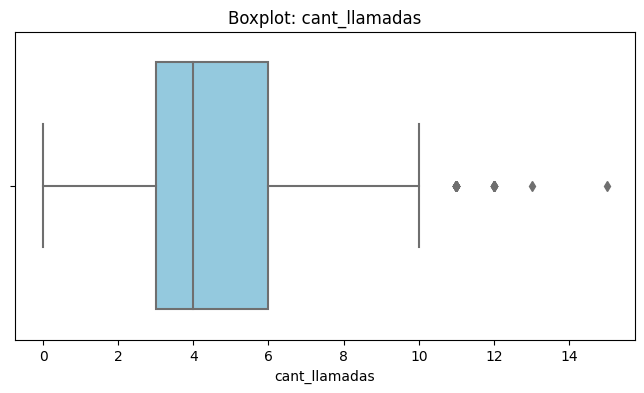

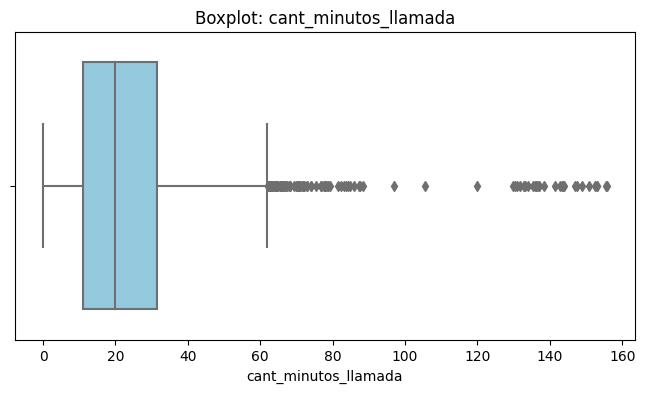

In [48]:

# Visualizando usando BoxPlot
columnas_numericas = [
    'age',
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

for col in columnas_numericas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=user_profile[col], color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights: 
- **Edad (`age`):** no se observan valores atípicos en el boxplot. El rango de edades parece razonable y no requiere correcciones con base en esta revisión visual.
- **Mensajes (`cant_mensajes`):** se observan valores atípicos en el extremo superior, correspondientes a usuarios con una cantidad de mensajes superior a la habitual. Se recomienda revisarlos antes de decidir si requieren tratamiento.
- **Llamadas (`cant_llamadas`):** se identifican valores atípicos superiores, asociados a usuarios con un número elevado de llamadas. Es necesario comprobar si corresponden a patrones reales de consumo.
- **Minutos de llamadas (`cant_minutos_llamada`):** se observa una cantidad considerable de valores atípicos superiores y una distribución sesgada hacia la derecha. Se recomienda calcular los límites IQR y revisar los registros extremos sin eliminarlos automáticamente.

In [49]:
# Calcular límites con el método IQR
columnas_limites = [
    'age',
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    print(f'\nVariable: {col}')
    print(f'Límite inferior: {limite_inferior:.2f}')
    print(f'Límite superior: {limite_superior:.2f}')



Variable: age
Límite inferior: -12.00
Límite superior: 108.00

Variable: cant_mensajes
Límite inferior: -0.50
Límite superior: 11.50

Variable: cant_llamadas
Límite inferior: -1.50
Límite superior: 10.50

Variable: cant_minutos_llamada
Límite inferior: -19.32
Límite superior: 61.86


In [50]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


💡Insights: 

- **Edad:** el máximo es de 79 años y se encuentra dentro de los límites IQR. No se identifican valores atípicos mediante este método.
- **Mensajes:** el máximo es de 17 mensajes, superior al límite de 11,50. Se identifican posibles valores atípicos que deben revisarse.
- **Llamadas:** el máximo es de 15 llamadas, superior al límite de 10,50. Se recomienda investigar los consumos elevados.
- **Minutos de llamadas:** el máximo es de 155,69 minutos, muy superior al límite de 61,86. Se deben revisar estos registros para determinar si representan patrones reales de uso o errores.
- **Decisión:** conservar inicialmente los valores atípicos y no eliminarlos sin comprobar su validez, pues pueden reflejar comportamientos legítimos de los clientes.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [51]:

# Crear columna grupo_uso

import numpy as np

condiciones = [
    (user_profile['cant_llamadas'] < 5) &
    (user_profile['cant_mensajes'] < 5),

    (user_profile['cant_llamadas'] < 10) &
    (user_profile['cant_mensajes'] < 10)
]

grupos = ['Bajo uso', 'Uso medio']

user_profile['grupo_uso'] = np.select(
    condiciones,
    grupos,
    default='Alto uso'
)


In [52]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [53]:

# Crear columna grupo_edad

condiciones_edad = [
    user_profile['age'] < 30,
    user_profile['age'] < 60
]

grupos_edad = ['Joven', 'Adulto']

user_profile['grupo_edad'] = np.select(
    condiciones_edad,
    grupos_edad,
    default='Adulto Mayor'
)


In [54]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

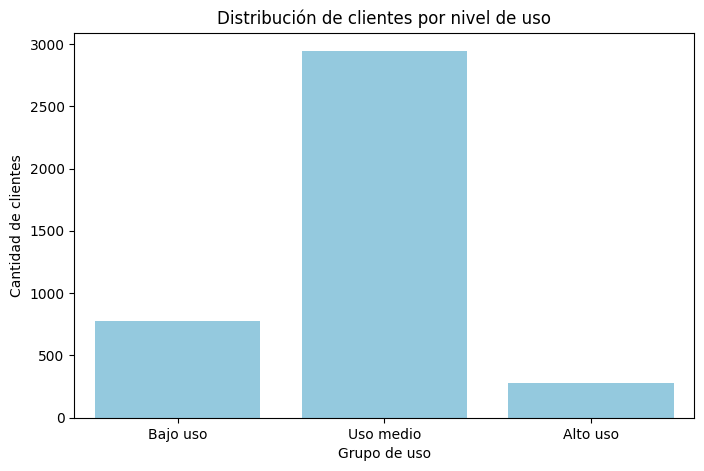

In [56]:


# Visualización de los segmentos por uso

plt.figure(figsize=(8, 5))

sns.countplot(
    data=user_profile,
    x='grupo_uso',
    order=['Bajo uso', 'Uso medio', 'Alto uso'],
    color='skyblue'
)

plt.title('Distribución de clientes por nivel de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de clientes')

plt.show()


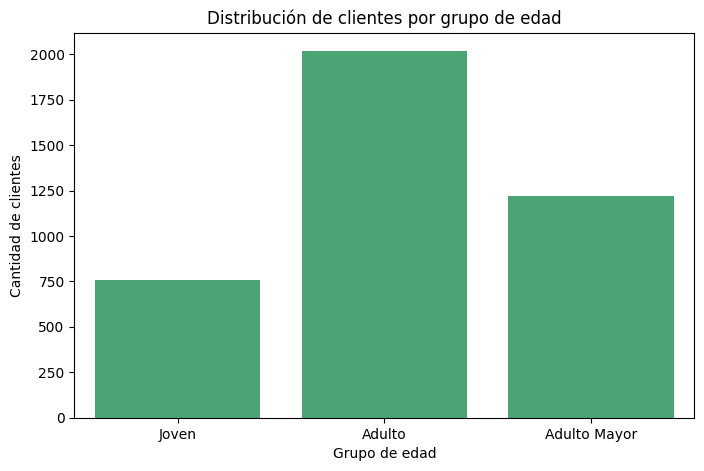

In [57]:

# Visualización de los segmentos por edad

plt.figure(figsize=(8, 5))

sns.countplot(
    data=user_profile,
    x='grupo_edad',
    order=['Joven', 'Adulto', 'Adulto Mayor'],
    color='mediumseagreen'
)

plt.title('Distribución de clientes por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de clientes')

plt.show()




---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**


### 📊 Análisis ejecutivo

### ⚠️ Problemas detectados en los datos

Durante la exploración se identificaron problemas de calidad que debían tratarse antes de realizar el análisis. En la tabla de clientes, la variable `age` contenía el valor centinela `-999`, que fue reemplazado por la mediana. También se identificaron valores faltantes y registros desconocidos en `city`, que fueron tratados como datos ausentes. Asimismo, se detectaron fechas de registro posteriores a 2024, las cuales se marcaron como nulas para evitar inconsistencias temporales.

En la tabla de uso, las variables `duration` y `length` presentaron valores faltantes asociados al tipo de actividad: las duraciones faltantes corresponden principalmente a mensajes de texto y las longitudes faltantes a llamadas. Por ello, se conservaron como nulas, dado que representan variables que no aplican a todos los tipos de actividad. También se identificaron posibles valores atípicos en las cantidades de mensajes, llamadas y minutos de llamadas, que deben investigarse antes de decidir si se mantienen o eliminan.

### 👥 Segmentos por edad

La segmentación identificó tres grupos: jóvenes (menores de 30 años), adultos (de 30 a 59 años) y adultos mayores (60 años o más). La visualización mostró que los adultos constituyen el grupo más numeroso, seguidos por los adultos mayores y los jóvenes.

Esta distribución permite reconocer que los adultos tienen una mayor representación dentro de la base de clientes. Sin embargo, la cantidad de usuarios por grupo no demuestra por sí sola que un segmento consuma más servicios que otro; para establecer esa relación es necesario comparar las métricas de uso entre los grupos de edad.

### 📱 Segmentos por nivel de uso

La segmentación por uso clasificó a los clientes en tres grupos según la cantidad de llamadas y mensajes registrados: bajo uso, uso medio y alto uso. Los resultados muestran un predominio del segmento de uso medio, mientras que el grupo de alto uso es el menos numeroso.

Este patrón indica que la mayoría de los clientes se encuentra en un nivel intermedio de actividad según las reglas definidas para el análisis. La segmentación puede servir como punto de partida para identificar necesidades diferenciadas, siempre que se complemente con información sobre los beneficios contratados, el consumo de datos móviles y los costos asociados a cada plan.

### 🔎 ¿Qué sugiere el análisis para ConnectaTel?

Los resultados iniciales muestran oportunidades para mejorar la calidad de los datos y comprender mejor el comportamiento de los clientes. Los valores atípicos deben revisarse para distinguir entre consumos legítimamente elevados y posibles errores de registro. Además, la distribución por edad y nivel de uso permite construir perfiles de clientes que pueden orientar análisis comerciales posteriores.

Con la información disponible hasta esta etapa, todavía no es posible concluir qué grupo es más rentable, presenta mayor riesgo de abandono o necesita migrar de plan. Estas decisiones requieren cruzar los segmentos con los planes contratados, el consumo real y, cuando corresponda, los ingresos o datos de cancelación.

### 💡 Recomendaciones

1. **Fortalecer la calidad de los datos:** documentar los valores centinela, revisar las fechas inválidas y mantener criterios consistentes para tratar los valores faltantes.
2. **Investigar los consumos atípicos:** revisar los clientes que superan los límites IQR para determinar si sus patrones son reales o si existen errores de registro.
3. **Profundizar la segmentación comercial:** comparar el uso de llamadas y mensajes por edad y tipo de plan para identificar diferencias reales entre los grupos.
4. **Evaluar la adecuación de los planes:** contrastar los consumos observados con los minutos y mensajes incluidos en cada plan para detectar oportunidades de mejora.
5. **Complementar el análisis antes de tomar decisiones:** incorporar métricas de ingresos, costos y cancelación cuando estén disponibles para evaluar rentabilidad, retención y posibles estrategias de migración.

**Conclusión general:** el análisis inicial permitió identificar problemas de calidad, caracterizar la distribución de los clientes y construir segmentos por edad y nivel de uso. Estos resultados constituyen una base para desarrollar estrategias comerciales diferenciadas, pero las decisiones definitivas deberán sustentarse en comparaciones adicionales entre consumo, planes contratados y resultados del negocio.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`